# TPI · Módulo 3 — Extracción de descriptores
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Detección de leucemia linfoblástica aguda (LLA) en imágenes de frotis de sangre periférica*

A partir de la segmentación calculamos números que describen cada célula, para después (Módulo 4) buscar cuáles separan las imágenes benignas de las patológicas. Según el anteproyecto, los linfoblastos tienen **núcleos más grandes, irregulares o hendidos, con alta relación núcleo/citoplasma y cromatina fina**, mientras que los linfocitos maduros y las hematogonias tienen núcleos más chicos, redondos y con cromatina densa.

Contenido:
1. **Diagnóstico de la segmentación de referencia** del dataset (por qué no la usamos).
2. **Segmentación de la célula** (núcleo + citoplasma) sin referencia, validada contra la referencia donde ésta funciona.
3. **Descriptores de forma** por célula (área, perímetro, circularidad, excentricidad, solidez, relación núcleo/célula).
4. Descriptores de color *(próximamente)*.
5. Descriptores de textura — GLCM y LBP *(próximamente)*.
6. Efecto de la compresión JPEG sobre los descriptores *(próximamente)*.

La salida es una tabla con una fila por imagen y una columna por descriptor (`modulo3_descriptores.csv`), que usa el Módulo 4.

## 0. Carga y funciones de los módulos anteriores
Mismo índice del dataset que en los Módulos 1 y 2, la corrección de iluminación por **cierre morfológico** (Módulo 1) y la segmentación del núcleo por ***k*-means global en (a\*, b\*)** (Módulo 2, sección 5). Se copian acá para que el notebook se pueda correr solo.

In [1]:
import os, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import spearmanr
from skimage import measure, segmentation
import kagglehub

RUTA = kagglehub.dataset_download('mehradaria/leukemia')
df = pd.DataFrame({'ruta': sorted(glob.glob(f'{RUTA}/**/*.jp*g', recursive=True))})
df['tipo'] = np.where(df.ruta.str.contains('segment', case=False), 'segmentada', 'original')
df['subtipo'] = df.ruta.map(lambda p: os.path.basename(os.path.dirname(p)))
df['clase'] = np.where(df.subtipo.str.contains('benign', case=False), 'no patológica', 'patológica')
df['archivo'] = df.ruta.map(os.path.basename)

org = df[df.tipo == 'original'].reset_index(drop=True)
seg = df[df.tipo == 'segmentada'].set_index(['subtipo', 'archivo']).ruta
org['ruta_seg'] = org.set_index(['subtipo', 'archivo']).index.map(seg.get)
org = org[org.ruta_seg.notna()].reset_index(drop=True)
leer = lambda ruta: cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)
subtipos = sorted(org.subtipo.unique())
print(f'Imágenes: {len(org)}')

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imágenes: 3256


In [2]:
# --- Módulo 1: corrección de iluminación (cierre morfológico) ---
TAM_EE = 1 / 3

def estimar_campo(v):
    n = max(v.shape)
    ee = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(n * TAM_EE) | 1,) * 2)
    return cv2.GaussianBlur(cv2.morphologyEx(v, cv2.MORPH_CLOSE, ee), (0, 0), n / 16)

def preprocesar(rgb):
    h, s, v = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))
    campo = np.maximum(estimar_campo(v.astype(np.float32)), 1)
    v = np.clip(v / campo * campo.mean(), 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2RGB)

# --- Módulo 2: limpieza morfológica y segmentación de referencia (sólo para validar) ---
AREA_MIN_NUC = 100     # px²: debajo es resto/ruido (histograma del área de componentes, commit anterior del Módulo 3)

def limpiar(mask, area_min=25):
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, etq, stats, _ = cv2.connectedComponentsWithStats(m)
    grandes = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= area_min]
    return np.isin(etq, grandes)

def sin_marca(mask):
    # Descarta la esquina inferior derecha (marca de agua / barra de escala).
    m = mask.copy(); h, w = m.shape
    m[int(h * 0.88):, int(w * 0.75):] = False
    return m

def mascara_celula(ruta_seg):
    # Segmentación de referencia del dataset (células completas). Sólo se usa para diagnóstico y validación.
    return cv2.cvtColor(leer(ruta_seg), cv2.COLOR_RGB2GRAY) > 10

def dice(a, b):
    return 2 * (a & b).sum() / (a.sum() + b.sum() + 1e-9)

## 1. Diagnóstico: la segmentación de referencia falla en Pro-B
Cada imagen tiene **varias células**, y la segmentación de referencia del dataset las marca a todas (más algunos restos). Pero en **Pro-B** viene vacía en muchas imágenes aunque se ven células violetas. Medimos, por subtipo, qué fracción de la imagen ocupa la referencia y cuántas imágenes la tienen prácticamente vacía (< 0,5 % de la imagen):

In [3]:
org['roi_frac'] = [mascara_celula(r).mean() for r in org.ruta_seg]
org.groupby('subtipo').roi_frac.agg(
    mediana='median',
    vacias=lambda x: (x < 0.005).sum(),
    pct_vacias=lambda x: 100 * (x < 0.005).mean()).round(3)

,mediana,vacias,pct_vacias
subtipo,,,
Benign,0.079,0,0.000
Early,0.090,0,0.000
Pre,0.214,0,0.000
Pro,0.011,146,18.159


**Resultado** (corrida completa): en Pro-B la referencia ocupa una mediana de **1,1 %** de la imagen (vs. 8–21 % en los demás subtipos) y está vacía en **146 imágenes (18 %)**. Por eso, en el Módulo 2 (sección 5) se reemplazó la segmentación del núcleo por ***k*-means global**, que no usa la referencia y recupera los núcleos de Pro-B (de 30 % a 0 % de imágenes sin núcleo).

Al dejar de usar la referencia perdemos también el contorno de la **célula completa**, necesario para la **relación núcleo/citoplasma**, uno de los criterios morfológicos clásicos del linfoblasto. La sección 2 lo resuelve.

## 2. Segmentación de la célula (núcleo + citoplasma) sin referencia
### 2.1 Método
El *k*-means global del Módulo 2 agrupa los píxeles en 3 clusters por color (a\*, b\*), ordenados por croma:
- **núcleo** (mayor croma: violeta intenso),
- **teñido intermedio**: citoplasma y glóbulos rojos,
- **fondo** (menor croma: plasma casi blanco).

Como el citoplasma es un celeste muy pálido, por croma puede confundirse con el fondo; por eso un píxel se considera **teñido** si no está en el cluster de fondo **o** si es más oscuro que el fondo (umbral de Otsu sobre la luminosidad L\*).

La **célula** de cada núcleo se arma "creciendo" el núcleo sobre los píxeles teñidos (no fondo) que lo rodean:
1. Cada píxel teñido se asigna al **núcleo más cercano** (transformada de distancia). Así, cuando dos células se tocan, el límite queda a mitad de camino entre sus núcleos.
2. Para no incorporar glóbulos rojos vecinos, el crecimiento se limita a un **anillo de ancho proporcional al tamaño del núcleo**: un píxel pertenece a la célula si está a una distancia del borde del núcleo menor que $(F-1)\cdot r_{eq}$, con $r_{eq}=\sqrt{A_{núcleo}/\pi}$. Con $F$ = 1,5 la célula puede tener hasta 1,5 veces el radio del núcleo.
3. Se rellenan huecos y se conserva sólo la parte conectada al núcleo.

El parámetro $F$ se elige con un **barrido** (*grid search*) contra la referencia (sección 2.2).

In [4]:
def kmeans_clusters(rgb, k=3):
    # k-means en (a*, b*) sobre todos los píxeles. Devuelve etiquetas ordenadas por croma: 0 = fondo, ..., k-1 = núcleo.
    ab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)[..., 1:].reshape(-1, 2) - 128
    _, etq, centros = cv2.kmeans(ab, k, None, (cv2.TERM_CRITERIA_EPS, 20, 0.5), 3, cv2.KMEANS_PP_CENTERS)
    orden = np.argsort(np.argsort(np.linalg.norm(centros, axis=1)))     # rango de croma de cada cluster
    return orden[etq.ravel()].reshape(rgb.shape[:2])

def segmentar_componentes(rgb):
    # Núcleos etiquetados (1..N) y máscara de píxeles teñidos (no fondo).
    cl = kmeans_clusters(rgb)
    nuc = sin_marca(ndi.binary_fill_holes(limpiar(cl == 2, AREA_MIN_NUC)))    # = segmentar_kmeans_global del Módulo 2
    # Teñido = no es fondo por color (cluster >= 1) O es más oscuro que el fondo (Otsu sobre L*):
    # el citoplasma es celeste muy pálido y por croma sólo puede confundirse con el fondo, pero es más oscuro.
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    umbral_L, _ = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tenido = sin_marca(limpiar((cl >= 1) | (L < umbral_L))) | nuc
    return measure.label(nuc), tenido

def crecer_celulas(nucleos, tenido, F):
    # Célula de cada núcleo: píxeles teñidos más cercanos a ese núcleo, dentro de un anillo de ancho (F-1)·r_eq.
    if nucleos.max() == 0:
        return np.zeros_like(nucleos)
    dist, (iy, ix) = ndi.distance_transform_edt(nucleos == 0, return_indices=True)
    mas_cercano = nucleos[iy, ix]
    areas = np.bincount(nucleos.ravel())
    r_eq = np.sqrt(areas / np.pi)
    celulas = np.where(tenido & (dist <= (F - 1) * r_eq[mas_cercano]), mas_cercano, 0)
    celulas[nucleos > 0] = nucleos[nucleos > 0]
    salida = np.zeros_like(celulas)
    for i in range(1, nucleos.max() + 1):                     # sólo la parte conectada al núcleo, sin huecos
        comp = measure.label(celulas == i)
        ids = np.unique(comp[nucleos == i]); ids = ids[ids > 0]
        salida[ndi.binary_fill_holes(np.isin(comp, ids))] = i
    return salida

### 2.2 Validación y elección de F
En **Benign, Early y Pre**, donde la referencia funciona, comparamos nuestras células con las de la referencia. Tomamos los núcleos que caen mayormente (> 50 %) dentro de la referencia y, para esos, medimos:
- **Dice** entre nuestras células y las células de la referencia que contienen esos núcleos;
- la **relación núcleo/célula** de la imagen calculada con nuestras células vs. con las de la referencia (**correlación de Spearman** y error absoluto medio).

**Criterio de aceptación (fijado antes de correr):** Dice medio ≥ 0,70 **y** Spearman ≥ 0,6 para el mejor $F$. Si no se cumple, se descarta la relación núcleo/célula y se usa como alternativa la fracción de la imagen ocupada por núcleos.

Se prueba también $F = 10$ (crecimiento prácticamente sin límite) como referencia de qué pasa si no se limita el anillo.

In [5]:
F_GRILLA = [1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 10]
muestra = org[~org.subtipo.str.contains('Pro')].groupby('subtipo').sample(40, random_state=0)
filas = []
for r in muestra.itertuples():
    rgb, roi = preprocesar(leer(r.ruta)), mascara_celula(r.ruta_seg)
    nucleos, tenido = segmentar_componentes(rgb)
    props = measure.regionprops(nucleos)
    adentro = [p.label for p in props if roi[nucleos == p.label].mean() > 0.5]
    if not adentro:
        continue
    nuc_ok = np.isin(nucleos, adentro)
    roi_lab = measure.label(roi)
    ids_ref = np.unique(roi_lab[nuc_ok]); ids_ref = ids_ref[ids_ref > 0]
    ref = np.isin(roi_lab, ids_ref)
    for F in F_GRILLA:
        cel = np.isin(crecer_celulas(nucleos, tenido, F), adentro)
        filas.append(dict(subtipo=r.subtipo, archivo=r.archivo, F=F, dice=dice(cel, ref),
                          nc_nuestra=nuc_ok.sum() / cel.sum(), nc_ref=(nuc_ok & ref).sum() / ref.sum()))
val = pd.DataFrame(filas)
tabla_F = val.groupby('F').apply(lambda g: pd.Series(dict(
    dice=g.dice.mean(),
    spearman_nc=spearmanr(g.nc_nuestra, g.nc_ref).correlation,
    error_nc=(g.nc_nuestra - g.nc_ref).abs().mean())), include_groups=False)
F_CITO = tabla_F.dice.idxmax()
print(f"Mejor F = {F_CITO}  ->  acepta: {tabla_F.loc[F_CITO, 'dice'] >= 0.70 and tabla_F.loc[F_CITO, 'spearman_nc'] >= 0.6}")
tabla_F.round(3)

Mejor F = 1.2  ->  acepta: False


,dice,spearman_nc,error_nc
F,,,
1.2,0.862,0.150,0.083
1.4,0.823,0.085,0.152
1.6,0.786,-0.035,0.210
1.8,0.752,-0.098,0.258
2.0,0.722,-0.132,0.296
2.5,0.666,-0.163,0.361
10.0,0.564,-0.150,0.461


In [6]:
# Detalle por subtipo con el F elegido
val[val.F == F_CITO].groupby('subtipo')[['dice', 'nc_nuestra', 'nc_ref']].mean().round(3)

,dice,nc_nuestra,nc_ref
subtipo,,,
Benign,0.823,0.749,0.803
Early,0.895,0.782,0.867
Pre,0.866,0.790,0.819


### 2.3 Ejemplos
Una imagen por subtipo (incluida Pro-B, donde no hay referencia para comparar): contorno **verde** = núcleo, **amarillo** = célula (núcleo + citoplasma) con el $F$ elegido, **rojo** punteado = referencia del dataset.

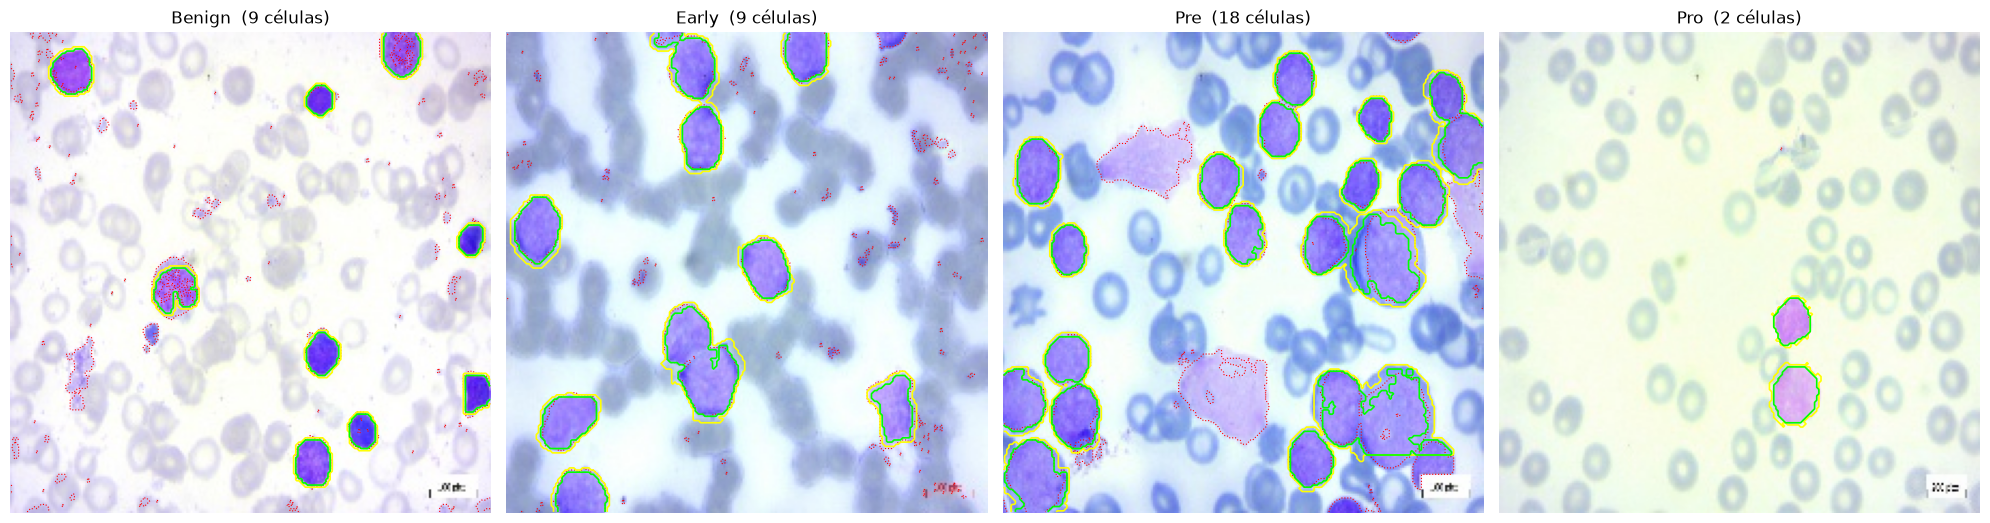

In [7]:
fig, ax = plt.subplots(1, len(subtipos), figsize=(5 * len(subtipos), 5.4))
for a, st in zip(ax, subtipos):
    r = org[org.subtipo == st].sample(1, random_state=1).iloc[0]
    rgb = preprocesar(leer(r.ruta))
    nucleos, tenido = segmentar_componentes(rgb)
    cel = crecer_celulas(nucleos, tenido, F_CITO)
    a.imshow(rgb)
    a.contour(mascara_celula(r.ruta_seg), [0.5], colors='red', linewidths=0.8, linestyles='dotted')
    a.contour(cel > 0, [0.5], colors='yellow', linewidths=1.2)
    a.contour(nucleos > 0, [0.5], colors='lime', linewidths=1.2)
    a.set_title(f'{st}  ({nucleos.max()} células)'); a.axis('off')
plt.tight_layout()

### 2.4 Conclusión de la sección 2
*(Completar después de correr: ¿se cumple el criterio? ¿qué F se eligió y por qué? ¿qué pasa sin límite de anillo (F = 10)?)*

## 3. Descriptores de forma
Se miden **célula por célula** y se resumen por imagen con la **mediana** (no se deja arrastrar por una célula mal segmentada). Las células que **tocan el borde** de la imagen están cortadas, así que se excluyen del cálculo de forma (si todas tocan el borde, se usan igual). La cantidad de núcleos sí cuenta todas.

| Descriptor | Qué mide | Qué esperamos en LLA |
|---|---|---|
| `area` | tamaño del núcleo [px²] | mayor |
| `perimetro` | largo del contorno del núcleo [px] | mayor |
| `circularidad` | $4\pi A / P^2$: 1 = círculo perfecto, baja si el borde es irregular | menor |
| `excentricidad` | 0 = círculo, →1 = alargado (elipse equivalente) | — |
| `solidez` | área / área de la envolvente convexa: < 1 si hay hendiduras | menor |
| `rel_nc` | área del núcleo / área de su célula (núcleo + citoplasma) | mayor (poco citoplasma) |
| `n_nucleos` | cantidad de núcleos detectados en la imagen | mayor (más blastos) |
| `frac_nuclear` | fracción de la imagen ocupada por núcleos (alternativa si `rel_nc` no valida) | mayor |

In [8]:
FORMA = ['area', 'perimetro', 'circularidad', 'excentricidad', 'solidez', 'rel_nc', 'n_nucleos', 'frac_nuclear']

def descriptores_forma(nucleos, celulas):
    # Resumen por imagen: mediana por célula (sin las que tocan el borde) + n_nucleos + frac_nuclear.
    d = dict(n_nucleos=int(nucleos.max()), frac_nuclear=(nucleos > 0).mean())
    internos = segmentation.clear_border(nucleos)
    usar = internos if internos.max() > 0 else nucleos
    area_cel = np.bincount(celulas.ravel(), minlength=nucleos.max() + 1)
    filas = []
    for p in measure.regionprops(usar):
        per = p.perimeter
        filas.append(dict(area=p.area, perimetro=per,
                          circularidad=4 * np.pi * p.area / per**2 if per > 0 else np.nan,
                          excentricidad=p.eccentricity, solidez=p.solidity,
                          rel_nc=p.area / area_cel[p.label] if area_cel[p.label] > 0 else np.nan))
    if not filas:
        return {**{k: np.nan for k in FORMA}, **d}
    return {**pd.DataFrame(filas).median().to_dict(), **d}

### 3.1 Cálculo sobre todo el dataset
Una pasada por las 3.256 imágenes (unos minutos). El resultado queda en la tabla `desc`, que se va completando en las secciones siguientes.

In [9]:
filas = []
for r in org.itertuples():
    rgb = preprocesar(leer(r.ruta))
    nucleos, tenido = segmentar_componentes(rgb)
    celulas = crecer_celulas(nucleos, tenido, F_CITO)
    filas.append(dict(archivo=r.archivo, subtipo=r.subtipo, clase=r.clase, **descriptores_forma(nucleos, celulas)))
desc = pd.DataFrame(filas)
print(f"Imágenes sin núcleo detectado: {(desc.n_nucleos == 0).sum()}  (por subtipo: {desc[desc.n_nucleos == 0].subtipo.value_counts().to_dict()})")
desc.groupby('subtipo')[FORMA].median().round(3)

Imágenes sin núcleo detectado: 0  (por subtipo: {})


,area,perimetro,circularidad,excentricidad,solidez,rel_nc,n_nucleos,frac_nuclear
subtipo,,,,,,,,
Benign,352.75,76.598,0.821,0.704,0.936,0.752,8.0,0.063
Early,484.00,84.426,0.854,0.710,0.953,0.784,6.0,0.065
Pre,424.50,80.234,0.864,0.711,0.953,0.792,18.0,0.166
Pro,373.00,73.380,0.879,0.719,0.955,0.784,6.0,0.042


### 3.2 Comparación entre clases
Boxplots de cada descriptor por subtipo. Buscamos descriptores donde la caja de **Benign** quede separada de las de los subtipos de LLA: son los candidatos para las reglas de clasificación del Módulo 4 (donde se evalúa formalmente con Mann-Whitney y curvas ROC).

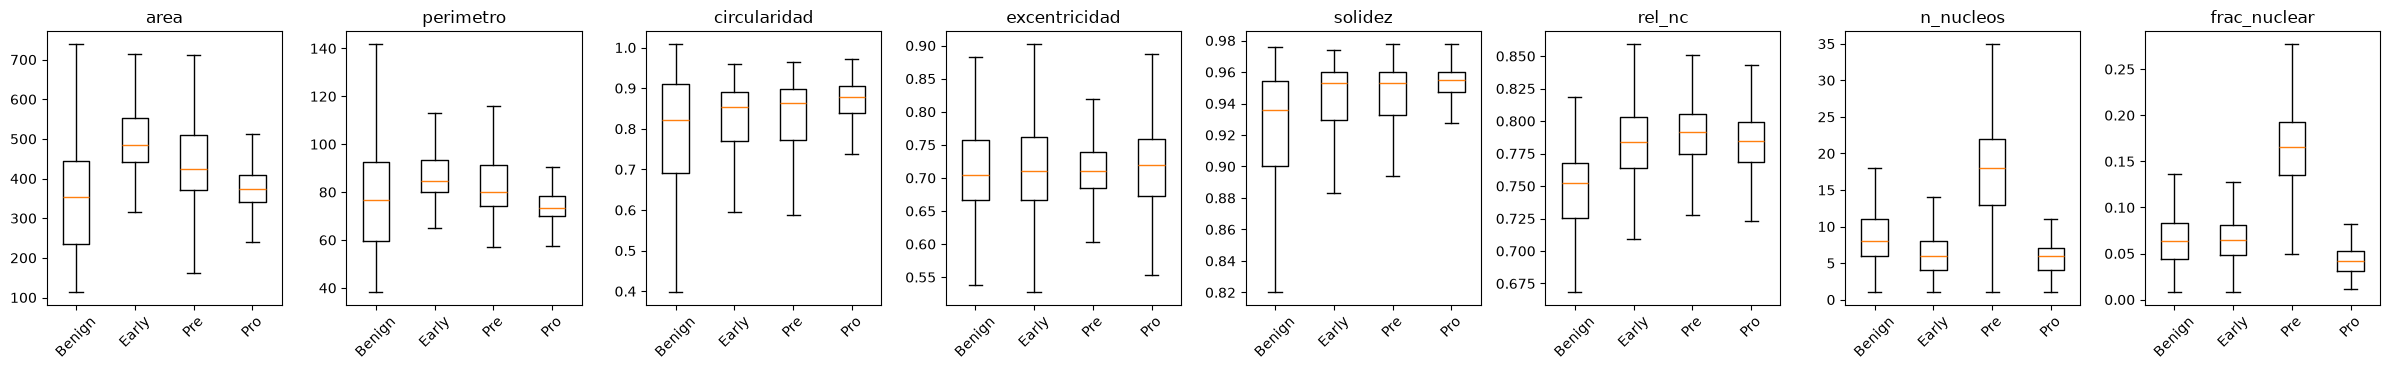

In [10]:
fig, ax = plt.subplots(1, len(FORMA), figsize=(3 * len(FORMA), 3.8))
for a, var in zip(ax, FORMA):
    a.boxplot([desc.loc[desc.subtipo == st, var].dropna() for st in subtipos], showfliers=False)
    a.set_xticks(range(1, len(subtipos) + 1), subtipos, rotation=45)
    a.set_title(var)
plt.tight_layout()

In [11]:
# Mediana por clase binaria del proyecto
desc.groupby('clase')[FORMA].median().round(3).T

clase,no patológica,patológica
area,352.750,432.000
perimetro,76.598,80.184
circularidad,0.821,0.865
excentricidad,0.704,0.713
solidez,0.936,0.954
rel_nc,0.752,0.787
n_nucleos,8.000,7.000
frac_nuclear,0.063,0.065


### 3.3 Observaciones
*(Completar después de correr.)*

In [12]:
desc.to_csv('modulo3_descriptores.csv', index=False)